# Transformer extension on GoEmotions sentiment — DistilBERT fine-tuning

**IT2-26** · Binary sentiment classification (0 = negative, 1 = positive) on the balanced 1,000-comment dataset. This notebook fine-tunes a small pretrained Transformer (DistilBERT) on the **same** train split used by the Dense, RNN and LSTM models and evaluates it once on the **same** test split, with the same five metrics.

Sections: setup, data, tokenization, training, evaluation, attention, discussion.

## Setup — which libraries, seed and hardware do we use?

Imports are grouped by library. The seed is fixed with `src.train.set_seed`, which also enables TensorFlow deterministic operations. The Hugging Face and TensorFlow log noise is lowered so the outputs do not print local paths.

In [1]:
import logging
import os
import platform
import random
import sys
import warnings
from pathlib import Path

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")  # library warnings print local file paths

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

root = Path.cwd().resolve()
if not (root / "src" / "evaluate.py").exists():
    root = root.parent
if not (root / "src" / "evaluate.py").exists():
    raise FileNotFoundError("Run this notebook from the project root or notebooks/ directory")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.chdir(root)  # src.train writes logs/ and outputs/ relative to the project root

logging.disable(logging.WARNING)  # TensorFlow/Keras deprecation warnings print local paths
import tensorflow as tf
import transformers

tf.get_logger().setLevel("ERROR")
transformers.logging.set_verbosity_error()

from src.evaluate import bootstrap_ci, evaluate_train_test, save_metrics
from src.models import DEFAULT_TRANSFORMER, build_transformer, tokenize_for_transformer
from src.train import SEED, Timer, get_logger, set_seed
from src.visualize import plot_confusion_matrix, plot_learning_curves

set_seed(SEED)
logging.disable(logging.NOTSET)  # Keras loads inside set_seed; warnings are on again from here
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0], "| TensorFlow:", tf.__version__, "| transformers:", transformers.__version__)
print("Machine:", platform.system(), platform.release(), "| logical CPUs:", os.cpu_count())
print("GPUs visible to TensorFlow:", tf.config.list_physical_devices("GPU") or "none (CPU only)")

Python: 3.11.18 | TensorFlow: 2.15.1 | transformers: 4.38.2
Machine: Windows 10 | logical CPUs: 12
GPUs visible to TensorFlow: none (CPU only)


**Insight:** the notebook runs on Python 3.11 with the pinned versions (TensorFlow 2.15.1, transformers 4.38.2) on a CPU with 12 logical cores and no GPU. Fine-tuning a 67M-parameter model on CPU is slow but feasible here because the dataset is tiny (800 training comments).

### Loading the dataset

The Transformer reads the **raw comment** (`text` column), not the stopword-free `clean_text` used by the TF-IDF and recurrent models. Its tokenizer and attention layers need the full sentence, including negations and function words. The rows and the labels are exactly the same as in the other models.

In [2]:
train = pd.read_csv(root / "data" / "processed" / "train.csv")
test = pd.read_csv(root / "data" / "processed" / "test.csv")

print("Train:", train.shape, "| Test:", test.shape)
print("Train class counts:", train["label"].value_counts().sort_index().to_dict())
print("Test class counts:", test["label"].value_counts().sort_index().to_dict())
assert train["text"].notna().all() and test["text"].notna().all()
train[["text", "label"]].head(3)

Train: (800, 4) | Test: (200, 4)
Train class counts: {0: 400, 1: 400}
Test class counts: {0: 100, 1: 100}


,text,label
0,I am sure the men here who have Career [NAME] ...,1
1,And the players who are older than me are reti...,0
2,The fact that you think like this is terrifying.,0


**Insight:** the splits are the same files used by every other model: 800 training comments (400 / 400) and 200 test comments (100 / 100). A model that guesses reaches accuracy near 0.50 and kappa near 0, so any score must be read against that line. The comments are kept raw, with `[NAME]` placeholders, punctuation and negations.

### Splitting the training rows — which rows choose the number of epochs?

The test split is untouched. From the 800 training rows we hold out a **stratified, seeded 20% validation set** (160 comments). The model is fitted on the other 640 rows and the validation loss decides which epoch to keep. This is the same protocol used for the RNN and LSTM (`fit_best_keras`).

In [3]:
X_train_text = train["text"].astype(str).tolist()
y_train = train["label"].to_numpy()
X_test_text = test["text"].astype(str).tolist()
y_test = test["label"].to_numpy()

fit_idx, val_idx = train_test_split(
    np.arange(len(train)), test_size=0.2, random_state=SEED, stratify=y_train
)
print("Fit rows:", len(fit_idx), "| Validation rows:", len(val_idx), "| Test rows:", len(y_test))
print("Validation class counts:", np.bincount(y_train[val_idx]).tolist())

Fit rows: 640 | Validation rows: 160 | Test rows: 200
Validation class counts: [80, 80]


### Tokenization — how long should the input be?

`tokenize_for_transformer` (IT2-25) follows slide 23: `truncation=True` and `padding="max_length"`, so every comment becomes a vector of the same length. Before fixing `max_length`, we measure the real token lengths of the training comments, without padding.

In [4]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(DEFAULT_TRANSFORMER)
lengths = np.array([len(ids) for ids in tokenizer(X_train_text)["input_ids"]])
MAX_LENGTH = 64

print("Token length (with [CLS] and [SEP]) -> mean: %.1f | median: %d | 95th pct: %d | max: %d"
      % (lengths.mean(), np.median(lengths), np.percentile(lengths, 95), lengths.max()))
print("Comments longer than MAX_LENGTH=%d (truncated): %d of %d" % (MAX_LENGTH, (lengths > MAX_LENGTH).sum(), len(lengths)))

enc_train = tokenize_for_transformer(X_train_text, max_length=MAX_LENGTH, tokenizer=tokenizer)
enc_test = tokenize_for_transformer(X_test_text, max_length=MAX_LENGTH, tokenizer=tokenizer)
print("input_ids train:", enc_train["input_ids"].shape, "| test:", enc_test["input_ids"].shape)
print("Example tokens:", tokenizer.convert_ids_to_tokens(enc_train["input_ids"][0][: int(enc_train["attention_mask"][0].sum())]))

Token length (with [CLS] and [SEP]) -> mean: 19.0 | median: 18 | 95th pct: 34 | max: 46
Comments longer than MAX_LENGTH=64 (truncated): 0 of 800
input_ids train: (800, 64) | test: (200, 64)
Example tokens: ['[CLS]', 'i', 'am', 'sure', 'the', 'men', 'here', 'who', 'have', 'career', '[', 'name', ']', 'and', 'super', '##mo', '##del', '[', 'name', ']', 'fighting', 'over', 'him', 'will', 'appreciate', 'this', 'sage', 'advice', '.', '[SEP]']


**Insight:** the training comments are short: mean 19 tokens, 95th percentile 34, maximum 46 (counting `[CLS]` and `[SEP]`). With `MAX_LENGTH = 64` **no comment is truncated**, so the model sees every word, and about 70% of every row (64 positions against a mean of 19 tokens) is padding that `attention_mask` hides from the attention. The WordPiece tokenizer splits rare words into pieces (`super ##mo ##del`) and keeps punctuation as separate tokens.

### What is a Transformer and how is it different from an LSTM?

An LSTM reads one token at a time and carries a hidden state, so information from the first word must survive many gated updates to reach the last one, and time step *t* cannot start before step *t − 1*. A Transformer replaces recurrence with **self-attention** (slide 23):

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d}}\right)V$$

Every token builds a query *Q*, a key *K* and a value *V*. The product *QKᵀ* scores every pair of tokens at once, the softmax turns each row into weights that add up to 1, and the output of each token is the weighted mix of all values. Two consequences: all positions are processed **in parallel**, and any two tokens are connected by **one step** (long-range dependencies do not fade through a hidden state). Positional encodings put the word order back, and multi-head attention repeats this with several sets of *Q*, *K*, *V*.

DistilBERT is a 6-layer, 12-head, 66M-parameter distilled version of BERT that is already pretrained on large text corpora. We keep its weights and fine-tune them with a new 2-class head (`num_labels=2`), exactly as in the BERT example of slide 23.

### Building the model — which configuration do we use?

No grid search is run: pretrained models are fine-tuned with a small, standard configuration (slide 23, `MASTER_PROMPT.md` §8): `lr = 2e-5`, batch size 16, up to 4 epochs, and the epoch is chosen with the validation loss. With 640 training rows, a full grid of 67M-parameter fine-tunings on CPU would take hours and would mostly fit noise.

In [5]:
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
MAX_EPOCHS = 4

set_seed(SEED)
transformer = build_transformer(DEFAULT_TRANSFORMER, num_labels=2, lr=LEARNING_RATE)

print("Parameters:", f"{transformer.count_params():,}")
print("Learning rate:", float(transformer.optimizer.learning_rate.numpy()))
print("Loss from_logits:", transformer.loss.get_config()["from_logits"])

Parameters: 66,955,010
Learning rate: 1.9999999494757503e-05
Loss from_logits: True


**Insight:** the model has 66,955,010 trainable parameters, about 84,000 times more than the number of training comments (800), which is why only a small learning rate (2e-5) is safe: a larger one would erase the pretrained knowledge. The learning rate and the `from_logits=True` loss are confirmed from the compiled model. The classification head is new; the other layers start from the pretrained weights.

### Training the model — how many epochs does the validation loss support?

`EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)` stops when the validation loss does not improve for one epoch and restores the best weights. With `patience=1` the restore always happens when it stops early. The wall-clock time is measured with `Timer` and logged to `logs/training_logs_transformer.txt`.

In [6]:
def select(enc, idx):
    return {key: value[idx] for key, value in enc.items()}

fit_inputs, y_fit = select(enc_train, fit_idx), y_train[fit_idx]
val_inputs, y_val = select(enc_train, val_idx), y_train[val_idx]

logger = get_logger("transformer")
logger.info(
    "Fine-tuning %s | lr=%s | batch=%d | max_epochs=%d | max_length=%d",
    DEFAULT_TRANSFORMER, LEARNING_RATE, BATCH_SIZE, MAX_EPOCHS, MAX_LENGTH,
)

set_seed(SEED)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=1, restore_best_weights=True
)
with Timer() as train_timer:
    history = transformer.fit(
        fit_inputs, y_fit,
        validation_data=(val_inputs, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=2,
    )

epochs_run = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
logger.info("Fine-tuning finished | epochs_run=%d | best_epoch=%d | seconds=%.1f | parameters=%d",
            epochs_run, best_epoch, train_timer.elapsed, transformer.count_params())

print("Epochs run:", epochs_run, "| best epoch (lowest validation loss):", best_epoch)
print("Training time: %.1f seconds (%.1f minutes) on CPU" % (train_timer.elapsed, train_timer.elapsed / 60))
pd.DataFrame(history.history).round(4).rename_axis("epoch").reset_index().assign(epoch=lambda d: d["epoch"] + 1)

Epoch 1/4


40/40 - 95s - loss: 0.6241 - accuracy: 0.6812 - val_loss: 0.4358 - val_accuracy: 0.8250 - 95s/epoch - 2s/step


Epoch 2/4


40/40 - 83s - loss: 0.3100 - accuracy: 0.8859 - val_loss: 0.4042 - val_accuracy: 0.8375 - 83s/epoch - 2s/step


Epoch 3/4


40/40 - 82s - loss: 0.1504 - accuracy: 0.9484 - val_loss: 0.3733 - val_accuracy: 0.8625 - 82s/epoch - 2s/step


Epoch 4/4


40/40 - 85s - loss: 0.0558 - accuracy: 0.9891 - val_loss: 0.4374 - val_accuracy: 0.8562 - 85s/epoch - 2s/step


Epochs run: 4 | best epoch (lowest validation loss): 3
Training time: 345.0 seconds (5.7 minutes) on CPU


,epoch,loss,accuracy,val_loss,val_accuracy
0,1,0.6241,0.6812,0.4358,0.8250
1,2,0.3100,0.8859,0.4042,0.8375
2,3,0.1504,0.9484,0.3733,0.8625
3,4,0.0558,0.9891,0.4374,0.8562


**Insight:** the training loss falls every epoch (0.62, 0.31, 0.15, 0.056), but the validation loss reaches its minimum at **epoch 3** (0.373) and rises at epoch 4 (0.437), while the training accuracy keeps growing (0.95 to 0.99). That is the start of overfitting, so the weights of epoch 3 are restored (validation accuracy 0.8625). The whole fine-tuning took between 5.7 and 6.8 minutes on this CPU (repeated runs gave the same losses; only the wall-clock time changes). Because the epoch was chosen on 160 validation comments, the validation accuracy is slightly optimistic and is not a final estimate.

### Learning curves — did the model converge or overfit?

Training and validation loss and accuracy by epoch. The weights restored by early stopping are those of the epoch with the lowest validation loss.

In [7]:
curve_fig = plot_learning_curves(history, name="transformer_learning_curves")
plt.show()

<Figure size 1200x400 with 2 Axes>

**Insight:** the validation curve is flat compared with the training curve: the model learns most of what it can from 640 comments in two or three epochs, and the gap between training and validation widens from epoch 2 on. Stopping at the minimum of the validation loss (epoch 3) is the honest choice; training for more epochs would only memorise.

### Predictions — when do we use the test set?

The model is now fixed (weights of the best epoch, no more tuning). We first predict on **all 800 training rows** to measure fit, as for the RNN and LSTM. Then the test split is used **once**. The model outputs logits; the predicted class is the one with the largest logit, and the softmax probability of the positive class is kept for the later comparison and error analysis.

In [8]:
def predict_labels(enc, batch_size=32):
    logits = transformer.predict(enc, batch_size=batch_size, verbose=0).logits
    probabilities = tf.nn.softmax(logits, axis=-1).numpy()[:, 1]
    return logits.argmax(axis=-1).astype(int), probabilities

with Timer() as predict_timer:
    transformer_pred_train, transformer_prob_train = predict_labels(enc_train)
print("Training predictions: positives %d of %d (%.1f s)" % (transformer_pred_train.sum(), len(transformer_pred_train), predict_timer.elapsed))

Training predictions: positives 394 of 800 (28.3 s)


In [9]:
# The test set is used here for the first and only time.
with Timer() as predict_timer:
    transformer_pred_test, transformer_prob_test = predict_labels(enc_test)
print("Test predictions: positives %d of %d (%.1f s)" % (transformer_pred_test.sum(), len(transformer_pred_test), predict_timer.elapsed))

Test predictions: positives 107 of 200 (8.3 s)


### Train and test metrics — does the Transformer generalise?

The same shared helper used for all models: accuracy, precision, recall and F1 for the positive class, macro F1 and Cohen's kappa. The CSV has one row per split.

In [10]:
transformer_metrics = evaluate_train_test(
    "transformer", y_train, transformer_pred_train, y_test, transformer_pred_test
)
metrics_path = save_metrics(transformer_metrics, "transformer")
print("Saved:", metrics_path.relative_to(root))
transformer_metrics.round(3)

Saved: outputs\metrics\transformer_metrics.csv


,model,split,accuracy,precision,recall,f1,f1_macro,kappa
0,transformer,train,0.965,0.972,0.958,0.965,0.965,0.93
1,transformer,test,0.895,0.869,0.930,0.899,0.895,0.79


**Insight:** the test accuracy is **0.895** and kappa **0.79**, with precision 0.869, recall 0.930 and F1 0.899. The training accuracy is 0.965 and kappa 0.93, so the gap is 0.07 in accuracy and 0.14 in kappa. In the earlier models the accuracy gap was 0.16 (LSTM), 0.22 (RNN) and 0.24 (Dense), so the pretrained Transformer overfits less and is also much better on the test split (LSTM 0.740 / kappa 0.480, Dense 0.720 / 0.440, RNN 0.675 / 0.350, best dummy 0.515 / 0.03). The comparison is not entirely like for like: the Transformer reads the raw text and brings knowledge learned from a large external corpus, which the other models do not have.

### How reliable is a score on 200 comments?

One test comment is 0.5 percentage points. We use the paired bootstrap helper of `src.evaluate` (2,000 resamples of the test pairs, seed 1234), the same one used in the model comparison, so the intervals can be compared across models.

In [11]:
acc_low, acc_high = bootstrap_ci(y_test, transformer_pred_test, "accuracy")
kappa_low, kappa_high = bootstrap_ci(y_test, transformer_pred_test, "kappa")
test_row = transformer_metrics.set_index("split").loc["test"]
print("Test accuracy %.3f, 95%% bootstrap CI [%.3f, %.3f]" % (test_row["accuracy"], acc_low, acc_high))
print("Test kappa    %.3f, 95%% bootstrap CI [%.3f, %.3f]" % (test_row["kappa"], kappa_low, kappa_high))

Test accuracy 0.895, 95% bootstrap CI [0.850, 0.935]
Test kappa    0.790, 95% bootstrap CI [0.698, 0.870]


**Insight:** the 95% bootstrap interval is [0.850, 0.935] for accuracy and [0.698, 0.870] for kappa. The interval of the LSTM in `outputs/metrics/model_comparison.csv` is [0.675, 0.795] for accuracy and [0.360, 0.590] for kappa. The intervals **do not overlap**, so on this test split the Transformer is better than the LSTM and than the Dense network, not just by chance of a few comments. Even so, the interval is wide (about 8 points) because there are only 200 test comments, and it comes from one fine-tuning run with one seed.

### Confusion matrix on the test set

Rows are the true labels and columns the predictions, ordered negative (0) and positive (1).

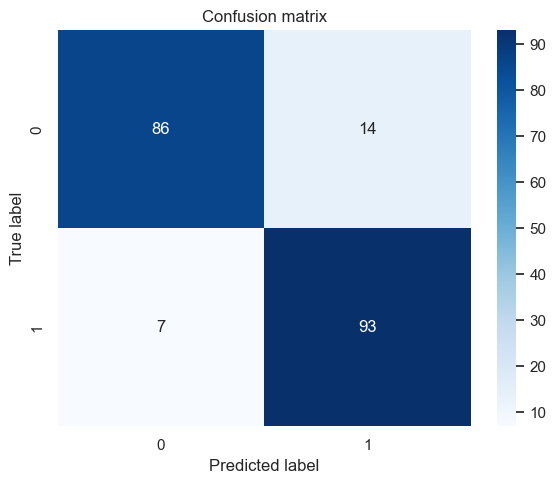

tn=86  fp=14  fn=7  tp=93


In [12]:
cm_fig = plot_confusion_matrix(y_test, transformer_pred_test, labels=[0, 1], name="transformer_confusion_matrix")
plt.show()
tn = int(((y_test == 0) & (transformer_pred_test == 0)).sum())
fp = int(((y_test == 0) & (transformer_pred_test == 1)).sum())
fn = int(((y_test == 1) & (transformer_pred_test == 0)).sum())
tp = int(((y_test == 1) & (transformer_pred_test == 1)).sum())
print(f"tn={tn}  fp={fp}  fn={fn}  tp={tp}")

**Insight:** the model gets 86 of 100 negatives and 93 of 100 positives right. It makes 14 false positives and 7 false negatives, so it leans slightly towards predicting positive (107 positive predictions for 100 true positives), which is why recall (0.930) is higher than precision (0.869). The 21 errors are too few to say which kind of comment causes them; the IT2-27 error analysis can check whether sarcasm, negation or slang explain them.

## Attention — what does the attention matrix show?

In the Neural Turing Machine (slides 21-22) the memory is an explicit matrix and the controller reads it with attention weights computed by **content addressing**. Self-attention uses the same idea inside the sequence: the *n × n* matrix `softmax(QKᵀ/√d)` is an explicit, inspectable table of how much each token reads from every other token. The difference is that the Transformer has no write head and no unbounded tape: its "memory" is the fixed context window (here 64 tokens) that is recomputed in every layer.

We inspect the **last layer averaged over the 12 heads**. DistilBERT classifies from the final representation of the `[CLS]` token, so its row says which tokens the classifier relies on most. Three test comments are chosen with a fixed rule: the first correctly classified positive, the first correctly classified negative and the first misclassified comment.

correct positive: [CLS] attends most to [('[SEP]', 0.29), ('thanks', 0.24), ('!', 0.22)]
   text: Thanks a lot!
correct negative: [CLS] attends most to [('tell', 0.21), ('.', 0.17), ('[SEP]', 0.16)]
   text: Tell him he needs to go to rehab or he’ll be kicked out.
misclassified: [CLS] attends most to [('not', 0.1), ('s', 0.1), ('close', 0.08)]
   text: I'm looking forward to this way more than Captain Marvel. It's actually not even close


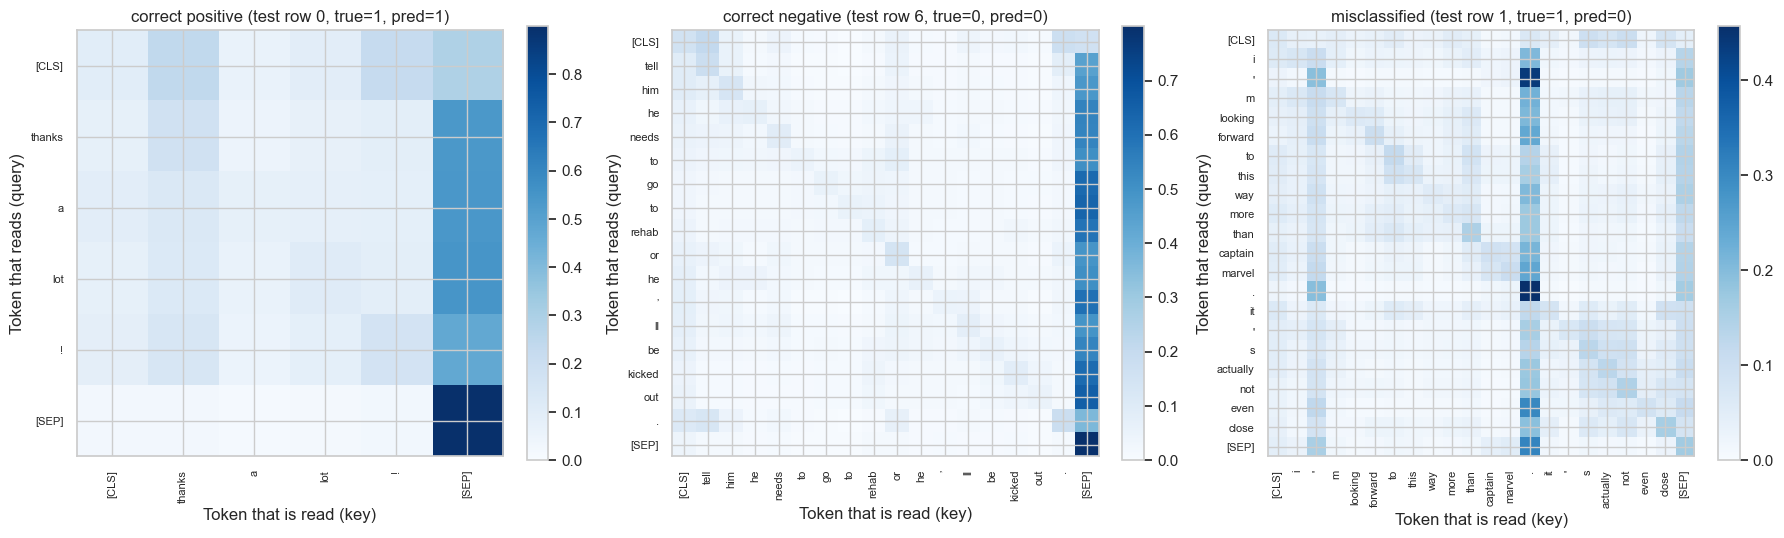

In [13]:
def first_index(mask):
    return int(np.flatnonzero(mask)[0])

correct = transformer_pred_test == y_test
chosen = {
    "correct positive": first_index(correct & (y_test == 1)),
    "correct negative": first_index(correct & (y_test == 0)),
    "misclassified": first_index(~correct),
}

sample = {key: value[list(chosen.values())] for key, value in enc_test.items()}
outputs = transformer(sample, output_attentions=True)
last_layer = outputs.attentions[-1].numpy().mean(axis=1)  # (3, seq, seq): mean over heads

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (title, row), matrix in zip(axes, chosen.items(), last_layer):
    n_real = int(sample["attention_mask"][list(chosen).index(title)].sum())
    tokens = tokenizer.convert_ids_to_tokens(sample["input_ids"][list(chosen).index(title)][:n_real])
    attention = matrix[:n_real, :n_real]
    # Each row is a softmax over the real tokens, so it must add up to about 1
    assert np.allclose(attention.sum(axis=1), 1.0, atol=1e-3), "rows of the attention matrix must sum to 1"
    im = ax.imshow(attention, cmap="Blues", vmin=0)
    ax.set_xticks(range(n_real), tokens, rotation=90, fontsize=8)
    ax.set_yticks(range(n_real), tokens, fontsize=8)
    ax.set(title=f"{title} (test row {row}, true={y_test[row]}, pred={transformer_pred_test[row]})",
           xlabel="Token that is read (key)", ylabel="Token that reads (query)")
    fig.colorbar(im, ax=ax, fraction=0.046)
    top = np.argsort(attention[0])[::-1][:3]
    print(f"{title}: [CLS] attends most to", [(tokens[i], round(float(attention[0][i]), 2)) for i in top])
    print("   text:", test["text"].iloc[row][:140])
fig.tight_layout()
fig.savefig(root / "outputs" / "figures" / "transformer_attention.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** every row of each matrix adds up to 1 (checked with an assertion), which is the softmax in `softmax(QKᵀ/√d)V`. In this last layer most tokens send a large part of their attention to `[SEP]` and to punctuation, a known behaviour in BERT-like models: these tokens work as a place to park attention when no other token is useful. The `[CLS]` row is spread over several tokens: in `Thanks a lot!` it looks at `thanks` (0.24) and `!` (0.22) besides `[SEP]` (0.29). The misclassified comment (`... It's actually not even close`, true label positive) is the sarcastic or ambiguous kind: `not` and `close` get some weight, but the attention is spread out and the model predicts negative. **Caution:** attention weights show where information flows in one layer; they are not a faithful explanation of the decision, so we use them as an illustration and not as proof.

## Discussion — attention versus recurrence

- **Recurrence versus attention:** an LSTM must pass information from the first token to the last one through a chain of gated updates, one step after another, so it cannot be parallelised over the sequence and distant words are connected through many steps. Self-attention connects every pair of tokens in a single step and computes all positions at the same time, which is why fine-tuning 640 comments takes seconds per step even on CPU. The price is memory: the attention matrix grows with the square of the sequence length (here 64 x 64 per head and layer).
- **Memory:** the LSTM keeps a compact state (the cell state) that is written and read at every step, so its memory is small, implicit and, in theory, unbounded. The Transformer keeps **all token representations** in the context window and reads them with the attention matrix, an explicit table like the memory matrix of the Neural Turing Machine (slides 21-22). It reads by content (queries against keys) but it has no write head and no tape that can grow: the window is fixed at 64 tokens, and anything outside it does not exist for the model.
- **Computation and generalisation:** both architectures are finite computations on a bounded input here, so none of them should be called a Turing machine in practice. In our data the largest difference comes less from the architecture than from **pretraining**: the Transformer arrives knowing English and needs only a few hundred examples, whereas the recurrent models learn their embeddings from 800 comments. We cannot separate the two effects with this experiment.
- **Limits of this evidence:** one run, one seed, 200 test comments, a validation set of 160 comments used to choose the epoch, and no hyperparameter search. The result supports 'the fine-tuned DistilBERT is clearly better than the other models on this split', not 'Transformers are always better'.

### Takeaways of the Transformer extension

- **Result:** DistilBERT fine-tuned for 3 effective epochs (`lr=2e-5`, batch 16, `max_length=64`) reaches test accuracy 0.895 and kappa 0.79, against 0.740 / 0.480 for the best earlier model (LSTM); the bootstrap intervals do not overlap.
- **Generalisation:** train accuracy 0.965 against test 0.895 is the smallest gap of the neural models; the validation loss shows overfitting from epoch 4.
- **Cost:** 67M parameters and 5.7 to 6.8 minutes of CPU fine-tuning (plus about 40 seconds to predict 1,000 comments); the Dense network is a much smaller model (see the parameter counts in IT2-27).
- **Interpretability:** the attention matrices are explicit and inspectable, but they are only an illustration, not a faithful explanation.
- **Limitations:** one seed, 200 test comments, no weights committed (re-running the notebook reproduces the numbers; fine-tuning takes about 6 to 7 minutes on this CPU).
- **Next step (IT2-27):** the variables `transformer_pred_test`, `transformer_prob_test`, `y_test` and `test` (raw text) are available for the five-model table and the error analysis.